# 19. Bilinear and Quadratic Forms
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

In [2]:
B = np.array([[0, 1, 6], [0, 2, 12], [0, 4, 24.]]); C = np.array([[1, -2, 9], [0, 1, -6], [0, 0, 1.]])
print("C^T B C =\n", C.T @ B @ C)

C^T B C =
 [[0. 1. 0.]
 [0. 0. 0.]
 [0. 1. 0.]]


The harmonic oscillator $\dot q=p$, $\dot p=-q$ integrated with step $h=0.1$ from a disc of initial states. Explicit Euler (left), whose step matrix $\begin{bmatrix}1&h\\-h&1\end{bmatrix}$ has determinant $1+h^2$, inflates both the orbit and the disc. Symplectic Euler (right), whose step matrix has determinant exactly $1$, keeps the disc's area and the orbit bounded.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


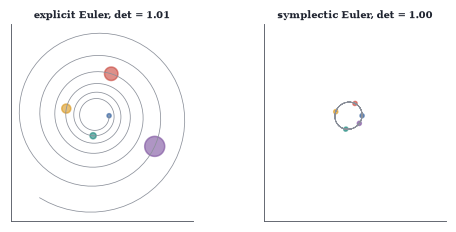

In [3]:
h = 0.1; E = np.array([[1, h], [-h, 1]]); Sy = np.array([[1, h], [0, 1]]) @ np.array([[1, 0], [-h, 1]])
t = np.linspace(0, 2 * np.pi, 200); disc = np.vstack([1.0 + 0.15 * np.cos(t), 0.15 * np.sin(t)])
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0), sharex=True, sharey=True)
for ax, M, ttl in [(axs[0], E, f"explicit Euler, det = {np.linalg.det(E):.2f}"), (axs[1], Sy, f"symplectic Euler, det = {np.linalg.det(Sy):.2f}")]:
    x = np.array([1.0, 0.0]); traj = [x]
    for k in range(400):
        x = M @ x; traj.append(x)
    traj = np.array(traj); ax.plot(*traj.T, color=GRAY, lw=0.5)
    D = disc.copy()
    for k, col in zip(range(0, 400, 80), [BLUE, TEAL, GOLD, RED, PLUM]):
        Dk = np.linalg.matrix_power(M, k) @ D; ax.fill(*Dk, color=col, alpha=0.6)
    ax.set_aspect("equal"); ax.set_title(ttl, fontsize=6.5); ax.set_xticks([]); ax.set_yticks([])

In [4]:
A = np.array([[1, -2, 4], [-2, 0, 0], [4, 0, -3.]])     # symmetric matrix of q
print("eigenvalues:", np.linalg.eigvalsh(A).round(4), "  signs: +", np.sum(np.linalg.eigvalsh(A) > 0), " -", np.sum(np.linalg.eigvalsh(A) < 0))
L = np.array([[1, 0, 0], [-2, 1, 0], [4, -2, 1.]]); D = np.diag([1, -4, -3.])
print("A = L D L^T:", np.allclose(L @ D @ L.T, A))

eigenvalues: [-5.6783 -0.5052  4.1835]   signs: + 1  - 2
A = L D L^T: True


The three nondegenerate central quadrics $q(x)=1$ in $\R^3$, determined by the signature of $q$: an ellipsoid $(3,0)$, a hyperboloid of one sheet $(2,1)$ and a hyperboloid of two sheets $(1,2)$. The principal axes are along the eigenvectors of the symmetric matrix of $q$.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


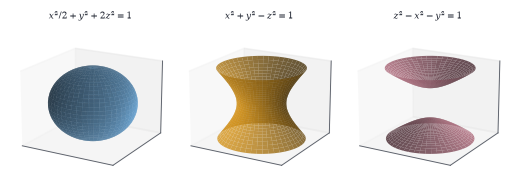

In [5]:
fig = plt.figure(figsize=(W, 1.9))
u = np.linspace(0, 2 * np.pi, 50); v = np.linspace(-1.2, 1.2, 30); U, Vv = np.meshgrid(u, v)
ax = fig.add_subplot(131, projection="3d"); th = np.linspace(0, np.pi, 30); Uu, Th = np.meshgrid(u, th)
ax.plot_surface(1.4 * np.sin(Th) * np.cos(Uu), 1.0 * np.sin(Th) * np.sin(Uu), 0.7 * np.cos(Th), color=SKY, alpha=0.8, lw=0); ax.set_title(r"$x^2/2+y^2+2z^2=1$", fontsize=6)
ax = fig.add_subplot(132, projection="3d")
ax.plot_surface(np.cosh(Vv) * np.cos(U), np.cosh(Vv) * np.sin(U), np.sinh(Vv), color=GOLD, alpha=0.8, lw=0); ax.set_title(r"$x^2+y^2-z^2=1$", fontsize=6)
ax = fig.add_subplot(133, projection="3d"); w = np.linspace(0, 1.4, 25); Uw, Ww = np.meshgrid(u, w)
for sgn in (1, -1):
    ax.plot_surface(np.sinh(Ww) * np.cos(Uw), np.sinh(Ww) * np.sin(Uw), sgn * np.cosh(Ww), color=ROSE, alpha=0.85, lw=0)
ax.set_title(r"$z^2-x^2-y^2=1$", fontsize=6)
for a in fig.axes:
    a.set_xticks([]); a.set_yticks([]); a.set_zticks([]); a.view_init(18, -60)

Critical points and their Hessians. A minimum (Hessian positive definite), a saddle (indefinite), and a degenerate "monkey saddle" $x^3-3xy^2$ whose Hessian at the origin is zero, so the quadratic test says nothing; three valleys and three ridges meet there.

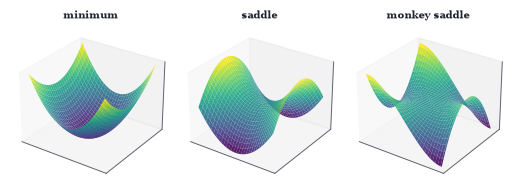

In [6]:
g = np.linspace(-1.2, 1.2, 60); X, Y = np.meshgrid(g, g)
fs = [(X ** 2 + 0.6 * Y ** 2, "minimum"), (X ** 2 - Y ** 2, "saddle"), (X ** 3 - 3 * X * Y ** 2, "monkey saddle")]
fig = plt.figure(figsize=(W, 1.8))
for i, (Z, ttl) in enumerate(fs):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d"); ax.plot_surface(X, Y, Z, cmap="viridis", lw=0, alpha=0.9)
    ax.set_title(ttl, fontsize=6.5); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(28, -55)

In [7]:
rng = np.random.default_rng(0)
for n in (2, 4, 6, 8, 10):
    trials = 40000; c = 0
    for _ in range(trials):
        G = rng.normal(size=(n, n)); c += np.all(np.linalg.eigvalsh(G + G.T) > 0)
    print(f"n = {n:2d}: fraction of random symmetric matrices that are positive definite = {c / trials:.5f}")

n =  2: fraction of random symmetric matrices that are positive definite = 0.14647


n =  4: fraction of random symmetric matrices that are positive definite = 0.00272


n =  6: fraction of random symmetric matrices that are positive definite = 0.00000


n =  8: fraction of random symmetric matrices that are positive definite = 0.00000


n = 10: fraction of random symmetric matrices that are positive definite = 0.00000


In [8]:
A = np.array([[1, 1, 0], [1, 3, 2], [0, 2, 1.]])
print("eigenvalues:", np.linalg.eigvalsh(A).round(4))

eigenvalues: [-0.4495  1.      4.4495]
